In [1]:
import pandas as pd

In [2]:
tickets = pd.read_excel("nexa_solicitacoes_iniciais.xlsx", sheet_name="Solicitacoes")

In [3]:
tickets.shape

(30, 7)

In [4]:
tickets.head()

,Ticket_ID,Data_abertura,Setor_solicitante,Setor_responsavel,Prioridade,Status,Data_resolucao
0,TK-0001,2026-08-06 09:00:00,Suporte Técnico,Financeiro,Média,Resolvido,2026-08-08 10:00:00
1,TK-0002,2026-08-09 10:00:00,Financeiro,Operações,Alta,Resolvido,2026-08-13 12:00:00
2,TK-0003,2026-08-12 11:00:00,Atendimento ao Cliente,Financeiro,Baixa,Resolvido,2026-08-19 14:00:00
3,TK-0004,2026-08-15 12:00:00,Operações,Suporte Técnico,Média,Resolvido,2026-08-26 12:00:00
4,TK-0005,2026-08-18 13:00:00,Suporte Técnico,Financeiro,Alta,Resolvido,2026-08-19 14:00:00


In [5]:
tickets.isnull().sum()

Ticket_ID            0
Data_abertura        0
Setor_solicitante    0
Setor_responsavel    0
Prioridade           0
Status               0
Data_resolucao       5
dtype: int64

In [6]:
tickets[
    (tickets["Status"] == "Resolvido") &
    (tickets["Data_resolucao"].isnull())
]

,Ticket_ID,Data_abertura,Setor_solicitante,Setor_responsavel,Prioridade,Status,Data_resolucao


In [7]:
tickets_resolvidos = tickets[tickets["Status"] == "Resolvido"]

In [8]:
tickets_resolvidos.shape

(25, 7)

In [9]:
tickets_resolvidos = tickets_resolvidos.copy()

In [10]:
tickets_resolvidos["Tempo_Resolucao"] = (
    tickets_resolvidos["Data_resolucao"] -
    tickets_resolvidos["Data_abertura"]
)

In [11]:
tickets_resolvidos.head()

,Ticket_ID,Data_abertura,Setor_solicitante,Setor_responsavel,Prioridade,Status,Data_resolucao,Tempo_Resolucao
0,TK-0001,2026-08-06 09:00:00,Suporte Técnico,Financeiro,Média,Resolvido,2026-08-08 10:00:00,2 days 01:00:00
1,TK-0002,2026-08-09 10:00:00,Financeiro,Operações,Alta,Resolvido,2026-08-13 12:00:00,4 days 02:00:00
2,TK-0003,2026-08-12 11:00:00,Atendimento ao Cliente,Financeiro,Baixa,Resolvido,2026-08-19 14:00:00,7 days 03:00:00
3,TK-0004,2026-08-15 12:00:00,Operações,Suporte Técnico,Média,Resolvido,2026-08-26 12:00:00,11 days 00:00:00
4,TK-0005,2026-08-18 13:00:00,Suporte Técnico,Financeiro,Alta,Resolvido,2026-08-19 14:00:00,1 days 01:00:00


In [12]:
tickets_resolvidos["Tempo_Resolucao"].mean()

Timedelta('5 days 01:33:36')

In [13]:
tickets_resolvidos["Tempo_Resolucao"].median()

Timedelta('4 days 02:00:00')

In [14]:
tickets_resolvidos["Tempo_Resolucao"].min()

Timedelta('1 days 00:00:00')

In [15]:
tickets_resolvidos["Tempo_Resolucao"].max()

Timedelta('11 days 03:00:00')

In [16]:
tickets_resolvidos["Tempo_Resolucao"].sort_values()

19    1 days 00:00:00
24    1 days 01:00:00
4     1 days 01:00:00
9     1 days 02:00:00
14    1 days 03:00:00
15    2 days 00:00:00
20    2 days 01:00:00
0     2 days 01:00:00
25    2 days 02:00:00
10    2 days 03:00:00
16    4 days 01:00:00
1     4 days 02:00:00
21    4 days 02:00:00
26    4 days 03:00:00
6     4 days 03:00:00
7     7 days 00:00:00
27    7 days 00:00:00
12    7 days 01:00:00
2     7 days 03:00:00
22    7 days 03:00:00
3    11 days 00:00:00
8    11 days 01:00:00
28   11 days 01:00:00
13   11 days 02:00:00
18   11 days 03:00:00
Name: Tempo_Resolucao, dtype: timedelta64[us]

<Axes: >

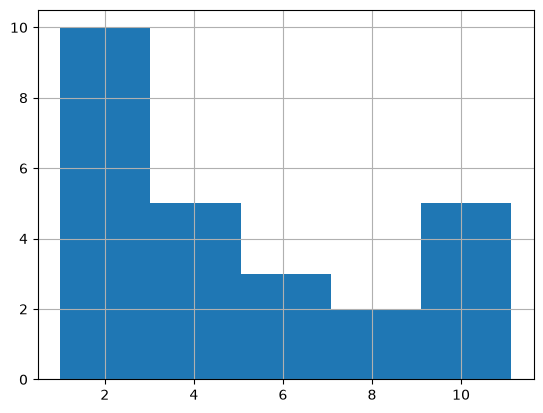

In [17]:
tickets_resolvidos["Tempo_Resolucao"].dt.total_seconds().div(86400).hist(bins=5)

In [18]:
tickets_resolvidos.columns

Index(['Ticket_ID', 'Data_abertura', 'Setor_solicitante', 'Setor_responsavel',
       'Prioridade', 'Status', 'Data_resolucao', 'Tempo_Resolucao'],
      dtype='str')

In [19]:
tickets_resolvidos.groupby("Setor_responsavel")["Tempo_Resolucao"].mean()

Setor_responsavel
Financeiro        5 days 01:56:00
Operações         4 days 11:36:00
Suporte Técnico   5 days 14:24:00
Name: Tempo_Resolucao, dtype: timedelta64[us]

In [20]:
tickets_resolvidos["Prioridade"].value_counts()

Prioridade
Média    10
Alta     10
Baixa     5
Name: count, dtype: int64

In [21]:
tickets_resolvidos.groupby("Prioridade")["Tempo_Resolucao"].mean()

Prioridade
Alta    5 days 01:30:00
Baixa   5 days 02:12:00
Média   5 days 01:18:00
Name: Tempo_Resolucao, dtype: timedelta64[us]

<Axes: xlabel='Prioridade'>

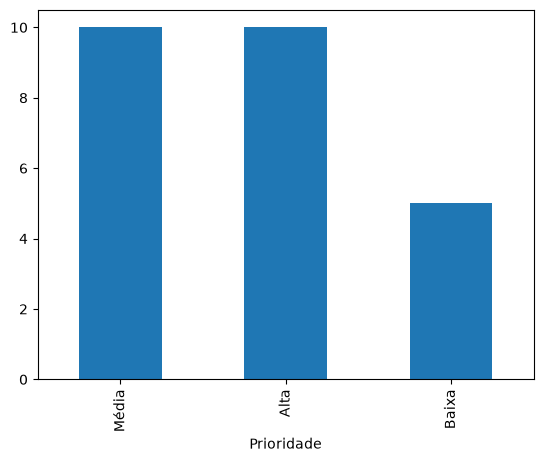

In [22]:
tickets_resolvidos["Prioridade"].value_counts().plot(kind="bar")

In [23]:
tempo_medio_setor = (tickets_resolvidos).groupby("Setor_responsavel")["Tempo_Resolucao"].mean().dt.total_seconds().div(86400)

<Axes: title={'center': 'Tempo médio de resolução por setor'}, xlabel='Setor responsável', ylabel='Tempo médio (dias)'>

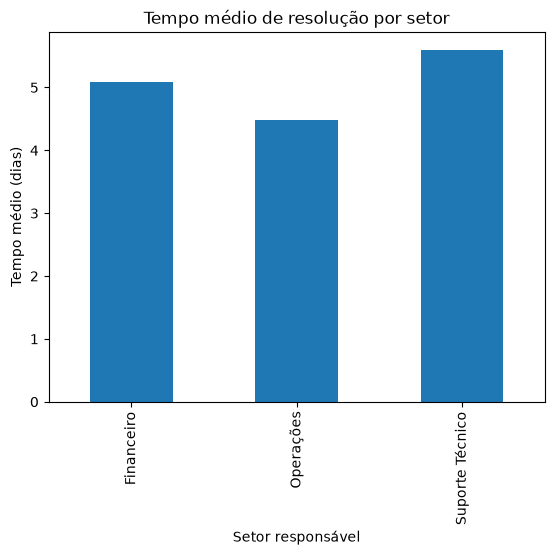

In [24]:
tempo_medio_setor.plot(kind="bar", title="Tempo médio de resolução por setor", xlabel="Setor responsável", ylabel="Tempo médio (dias)")

In [25]:
total_tickets = tickets.shape[0]

total_resolvidos = tickets_resolvidos.shape[0]

total_nao_resolvidos = total_tickets - total_resolvidos

taxa_resolucao = (total_resolvidos / total_tickets) * 100

print("Total de solicitações:", total_tickets)
print("Solicitações resolvidas:", total_resolvidos)
print("Solicitações não resolvidas:", total_nao_resolvidos)
print("Taxa de resolução:", round(taxa_resolucao, 2), "%")

Total de solicitações: 30
Solicitações resolvidas: 25
Solicitações não resolvidas: 5
Taxa de resolução: 83.33 %


In [26]:
tickets_pendentes = tickets[tickets["Status"] != "Resolvido"].copy()

tickets_pendentes

,Ticket_ID,Data_abertura,Setor_solicitante,Setor_responsavel,Prioridade,Status,Data_resolucao
5,TK-0006,2026-08-21 14:00:00,Financeiro,Operações,Baixa,Em andamento,NaT
11,TK-0012,2026-08-12 12:00:00,Operações,Suporte Técnico,Baixa,Em andamento,NaT
17,TK-0018,2026-08-03 10:00:00,Financeiro,Operações,Baixa,Em andamento,NaT
23,TK-0024,2026-08-21 08:00:00,Operações,Suporte Técnico,Baixa,Em andamento,NaT
29,TK-0030,2026-08-12 14:00:00,Financeiro,Operações,Baixa,Em andamento,NaT


In [27]:
tickets_pendentes["Setor_responsavel"].value_counts()

Setor_responsavel
Operações          3
Suporte Técnico    2
Name: count, dtype: int64

In [28]:
total_por_setor = tickets["Setor_responsavel"].value_counts()

pendentes_por_setor = tickets_pendentes["Setor_responsavel"].value_counts()

taxa_pendencias = (pendentes_por_setor.reindex(total_por_setor.index, fill_value=0).div(total_por_setor).mul(100))

taxa_pendencias

Setor_responsavel
Financeiro          0.000000
Operações          37.500000
Suporte Técnico    28.571429
Name: count, dtype: float64

In [33]:
data_referencia = pd.Timestamp("2026-08-31 23:59:59")

tickets_pendentes["Tempo_Em_Aberto"] = (data_referencia - tickets_pendentes["Data_abertura"])

tickets_pendentes[["Ticket_ID", "Setor_responsavel", "Prioridade", "Tempo_Em_Aberto"]]

,Ticket_ID,Setor_responsavel,Prioridade,Tempo_Em_Aberto
5,TK-0006,Operações,Baixa,10 days 09:59:59
11,TK-0012,Suporte Técnico,Baixa,19 days 11:59:59
17,TK-0018,Operações,Baixa,28 days 13:59:59
23,TK-0024,Suporte Técnico,Baixa,10 days 15:59:59
29,TK-0030,Operações,Baixa,19 days 09:59:59


In [34]:
resumo_gerencial = pd.DataFrame({"Indicador":["Total de solicitações", "Solicitações resolvidas", "Solicitações pendentes", "Taxa de resolução (%)"], "Valor":[total_tickets, total_resolvidos, total_nao_resolvidos, round(taxa_resolucao, 2)]})

resumo_gerencial

,Indicador,Valor
0,Total de solicitações,30.00
1,Solicitações resolvidas,25.00
2,Solicitações pendentes,5.00
3,Taxa de resolução (%),83.33


In [36]:
resumo_gerencial.to_excel("nexa_resumo_gerencial.xlsx", sheet_name="Indicadores", index=False)